In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/jess-hollander/DS4420-Project/main/data/games.csv"

df = pd.read_csv(url)

df.head()


,GAME_ID,SEASON,GAME_DATE,NEUTRAL,HOME_TEAM_ID,HOME_TEAM_ABBREVIATION,HOME_PTS,HOME_FGM,HOME_FGA,HOME_FG3M,...,AWAY_OREB,AWAY_DREB,AWAY_REB,AWAY_AST,AWAY_STL,AWAY_BLK,AWAY_TOV,AWAY_PF,HOME_WIN,POINT_DIFF
0,22100001,2021-22,2021-10-19,0,1610612749,MIL,127,48,105,17,...,5,39,44,19,3,9,13,17,1,23
1,22100002,2021-22,2021-10-19,0,1610612747,LAL,114,45,95,15,...,9,41,50,30,9,2,17,18,0,-7
2,22100003,2021-22,2021-10-20,0,1610612766,CHA,123,46,107,13,...,8,43,51,29,2,10,17,24,1,1
3,22100004,2021-22,2021-10-20,0,1610612765,DET,88,36,90,6,...,9,39,48,18,8,5,17,19,0,-6
4,22100005,2021-22,2021-10-20,0,1610612752,NYK,138,51,105,17,...,15,41,56,34,13,9,18,24,1,4


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nNumber of games per season:")
print(df["SEASON"].value_counts().sort_index())

print("\nTotal missing values:")
print(df.isnull().sum().sum())


Dataset shape: (6150, 40)

Column names:
['GAME_ID', 'SEASON', 'GAME_DATE', 'NEUTRAL', 'HOME_TEAM_ID', 'HOME_TEAM_ABBREVIATION', 'HOME_PTS', 'HOME_FGM', 'HOME_FGA', 'HOME_FG3M', 'HOME_FG3A', 'HOME_FTM', 'HOME_FTA', 'HOME_OREB', 'HOME_DREB', 'HOME_REB', 'HOME_AST', 'HOME_STL', 'HOME_BLK', 'HOME_TOV', 'HOME_PF', 'AWAY_TEAM_ID', 'AWAY_TEAM_ABBREVIATION', 'AWAY_PTS', 'AWAY_FGM', 'AWAY_FGA', 'AWAY_FG3M', 'AWAY_FG3A', 'AWAY_FTM', 'AWAY_FTA', 'AWAY_OREB', 'AWAY_DREB', 'AWAY_REB', 'AWAY_AST', 'AWAY_STL', 'AWAY_BLK', 'AWAY_TOV', 'AWAY_PF', 'HOME_WIN', 'POINT_DIFF']

Number of games per season:
SEASON
2021-22    1230
2022-23    1230
2023-24    1230
2024-25    1230
2025-26    1230
Name: count, dtype: int64

Total missing values:
0


In [3]:
# Prepare home team scoring records
home = df[["GAME_ID", "GAME_DATE", "SEASON",
           "HOME_TEAM_ABBREVIATION", "HOME_PTS"]].copy()

home = home.rename(columns={
    "HOME_TEAM_ABBREVIATION": "TEAM",
    "HOME_PTS": "PTS"
})

# Prepare away team scoring records
away = df[["GAME_ID", "GAME_DATE", "SEASON",
           "AWAY_TEAM_ABBREVIATION", "AWAY_PTS"]].copy()

away = away.rename(columns={
    "AWAY_TEAM_ABBREVIATION": "TEAM",
    "AWAY_PTS": "PTS"
})

# Combine home and away records
team_games = pd.concat([home, away], ignore_index=True)

# Sort games chronologically for each team
team_games["GAME_DATE"] = pd.to_datetime(team_games["GAME_DATE"])

team_games = team_games.sort_values(
    ["TEAM", "GAME_DATE", "GAME_ID"]
).reset_index(drop=True)

print("Dataset shape:", team_games.shape)
print("Number of teams:", team_games["TEAM"].nunique())

team_games.head(10)


Dataset shape: (12300, 5)
Number of teams: 30


,GAME_ID,GAME_DATE,SEASON,TEAM,PTS
0,22100014,2021-10-21,2021-22,ATL,113
1,22100027,2021-10-23,2021-22,ATL,95
2,22100043,2021-10-25,2021-22,ATL,122
3,22100059,2021-10-27,2021-22,ATL,102
4,22100066,2021-10-28,2021-22,ATL,111
5,22100082,2021-10-30,2021-22,ATL,94
6,22100097,2021-11-01,2021-22,ATL,118
7,22100113,2021-11-03,2021-22,ATL,108
8,22100120,2021-11-04,2021-22,ATL,98
9,22100137,2021-11-06,2021-22,ATL,117


In [4]:
# Split data chronologically by season
train = team_games[team_games["SEASON"] != "2025-26"].copy()
test = team_games[team_games["SEASON"] == "2025-26"].copy()

print("Training records:", len(train))
print("Testing records:", len(test))

print("\nTraining seasons:", train["SEASON"].unique())
print("Testing seasons:", test["SEASON"].unique())

print("\nTraining records per team:")
print(train.groupby("TEAM").size().head())


Training records: 9840
Testing records: 2460

Training seasons: ['2021-22' '2022-23' '2023-24' '2024-25']
Testing seasons: ['2025-26']

Training records per team:
TEAM
ATL    328
BKN    328
BOS    328
CHA    328
CHI    328
dtype: int64


In [5]:
from statsmodels.tsa.ar_model import AutoReg

# Get Atlanta's training scores
atl_train = train[train["TEAM"] == "ATL"]["PTS"].reset_index(drop=True)

# Fit an AR(3) model
ar_model = AutoReg(atl_train, lags=3).fit()

# Display model results
print(ar_model.summary())


                            AutoReg Model Results                             
Dep. Variable:                    PTS   No. Observations:                  325
Model:                     AutoReg(3)   Log Likelihood               -1269.323
Method:               Conditional MLE   S.D. of innovations             12.021
Date:                Tue, 24 Nov 2026   AIC                           2548.646
Time:                        00:35:48   BIC                           2567.566
Sample:                             3   HQIC                          2556.197
                                  328                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         94.7406     10.173      9.313      0.000      74.801     114.680
PTS.L1         0.0929      0.055      1.676      0.094      -0.016       0.202
PTS.L2         0.0911      0.055      1.652      0.0

In [6]:
# Compare lag orders for all 30 teams
lag_results = []

for team in train["TEAM"].unique():

    scores = train[train["TEAM"] == team]["PTS"].reset_index(drop=True)

    for p in range(1, 11):

        model = AutoReg(scores, lags=p, hold_back=10).fit()

        lag_results.append({
            "TEAM": team,
            "LAG": p,
            "AIC": model.aic
        })

lag_results = pd.DataFrame(lag_results)

# Calculate average AIC across all teams
aic_comparison = lag_results.groupby("LAG")["AIC"].mean()

print(aic_comparison)

# Select the best common lag order
best_p = int(aic_comparison.idxmin())

print("\nBest lag order:", best_p)


LAG
1     2500.386477
2     2498.594891
3     2497.593357
4     2497.148998
5     2496.117035
6     2495.560240
7     2495.572817
8     2495.391994
9     2495.816684
10    2496.876673
Name: AIC, dtype: float64

Best lag order: 8


In [7]:
import numpy as np

predictions = []

# Train a separate AR model for each team
for team in train["TEAM"].unique():

    train_scores = train[train["TEAM"] == team]["PTS"].tolist()

    team_test = test[test["TEAM"] == team].copy()

    # Fit the selected AR model
    model = AutoReg(train_scores, lags=best_p).fit()

    coefficients = np.asarray(model.params)
    history = train_scores.copy()

    # Predict each test game using previous scores
    for _, row in team_test.iterrows():

        recent_scores = np.array(history[-best_p:][::-1])

        predicted_pts = (
            coefficients[0]
            + np.dot(coefficients[1:], recent_scores)
        )

        predictions.append({
            "GAME_ID": row["GAME_ID"],
            "TEAM": team,
            "ACTUAL_PTS": row["PTS"],
            "PREDICTED_PTS": predicted_pts
        })

        # Add actual score only after making prediction
        history.append(row["PTS"])

predictions_df = pd.DataFrame(predictions)

print("Total predictions:", len(predictions_df))

predictions_df.head(10)


Total predictions: 2460


,GAME_ID,TEAM,ACTUAL_PTS,PREDICTED_PTS
0,22500082,ATL,118,120.795551
1,22500090,ATL,111,116.096207
2,22500101,ATL,100,116.896582
3,22500115,ATL,123,118.461592
4,22500130,ATL,117,115.390051
5,22500020,ATL,128,119.523802
6,22500151,ATL,109,118.014604
7,22500166,ATL,127,116.204125
8,22500030,ATL,97,119.285882
9,22500185,ATL,122,116.092453


In [8]:
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error

# Get original test-season games
test_games = df[df["SEASON"] == "2025-26"].copy()

# Match predicted scores to home and away teams
home_pred = predictions_df.rename(columns={
    "TEAM": "HOME_TEAM_ABBREVIATION",
    "PREDICTED_PTS": "HOME_PRED"
})

away_pred = predictions_df.rename(columns={
    "TEAM": "AWAY_TEAM_ABBREVIATION",
    "PREDICTED_PTS": "AWAY_PRED"
})

test_games = test_games.merge(
    home_pred[["GAME_ID", "HOME_TEAM_ABBREVIATION", "HOME_PRED"]],
    on=["GAME_ID", "HOME_TEAM_ABBREVIATION"]
)

test_games = test_games.merge(
    away_pred[["GAME_ID", "AWAY_TEAM_ABBREVIATION", "AWAY_PRED"]],
    on=["GAME_ID", "AWAY_TEAM_ABBREVIATION"]
)

# Predict the winning team
test_games["PRED_HOME_WIN"] = (
    test_games["HOME_PRED"] > test_games["AWAY_PRED"]
).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(
    test_games["HOME_WIN"],
    test_games["PRED_HOME_WIN"]
)

mae = mean_absolute_error(
    predictions_df["ACTUAL_PTS"],
    predictions_df["PREDICTED_PTS"]
)

rmse = np.sqrt(mean_squared_error(
    predictions_df["ACTUAL_PTS"],
    predictions_df["PREDICTED_PTS"]
))

print("Games evaluated:", len(test_games))
print(f"AR({best_p}) Accuracy: {accuracy:.2%}")
print(f"MAE: {mae:.2f} points")
print(f"RMSE: {rmse:.2f} points")


Games evaluated: 1230
AR(8) Accuracy: 54.88%
MAE: 10.53 points
RMSE: 13.19 points


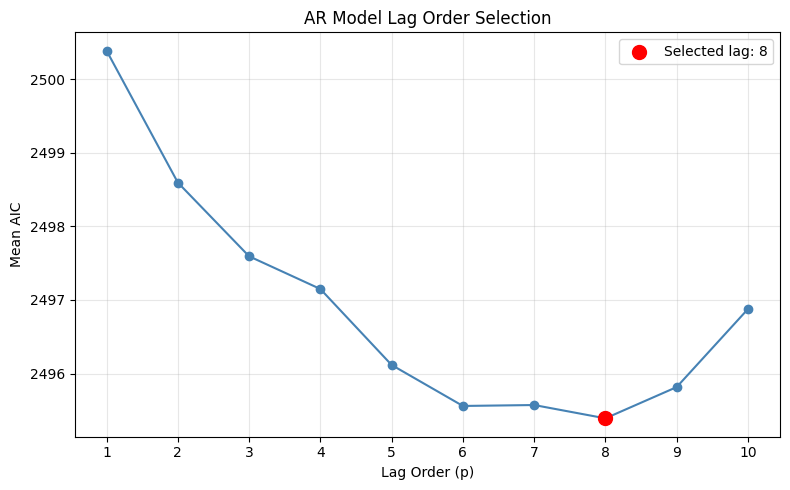

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(aic_comparison.index, aic_comparison.values,
         marker="o", color="steelblue")

plt.scatter(best_p, aic_comparison.loc[best_p],
            color="red", s=100, zorder=5,
            label=f"Selected lag: {best_p}")

plt.xlabel("Lag Order (p)")
plt.ylabel("Mean AIC")
plt.title("AR Model Lag Order Selection")
plt.xticks(range(1, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figure3_lag_selection.png", dpi=300)
plt.show()


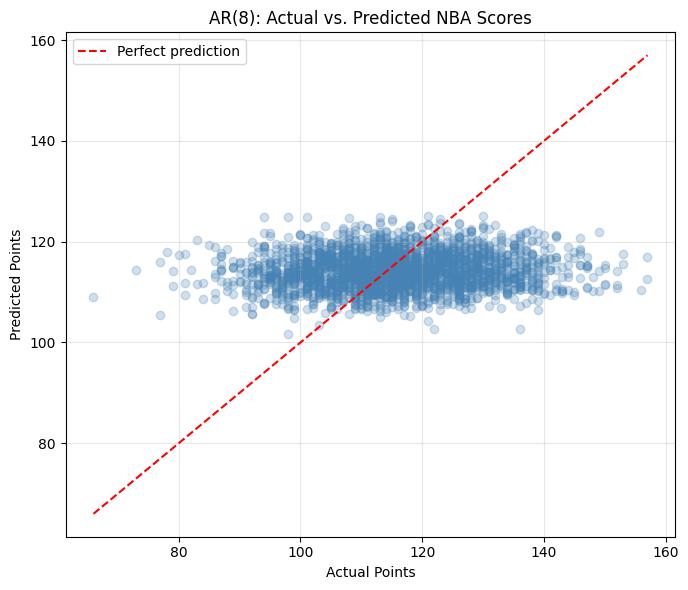

In [10]:
plt.figure(figsize=(7, 6))

plt.scatter(
    predictions_df["ACTUAL_PTS"],
    predictions_df["PREDICTED_PTS"],
    alpha=0.25,
    color="steelblue"
)

lower = min(predictions_df["ACTUAL_PTS"].min(),
            predictions_df["PREDICTED_PTS"].min())

upper = max(predictions_df["ACTUAL_PTS"].max(),
            predictions_df["PREDICTED_PTS"].max())

plt.plot([lower, upper], [lower, upper],
         "r--", label="Perfect prediction")

plt.xlabel("Actual Points")
plt.ylabel("Predicted Points")
plt.title("AR(8): Actual vs. Predicted NBA Scores")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("figure4_score_predictions.png", dpi=300)
plt.show()
